In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings('ignore')

In [13]:
df = pd.read_csv("WineQT.csv")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [14]:
df.shape

(1143, 13)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [16]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


Transformação da variável qualidade em classificação binária:

Alta Qualidade = nota ≥ 7
Baixa/Média Qualidade = nota < 7

In [17]:
df['quality_class'] = np.where(df['quality'] >= 7, 1, 0)

df['quality_class'].value_counts()

,count
quality_class,
0,984
1,159


In [18]:
df['quality_class'].value_counts(normalize=True)*100

,proportion
quality_class,
0,86.089239
1,13.910761


Verficação de valores ausentes

In [19]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Distribuição das variáveis

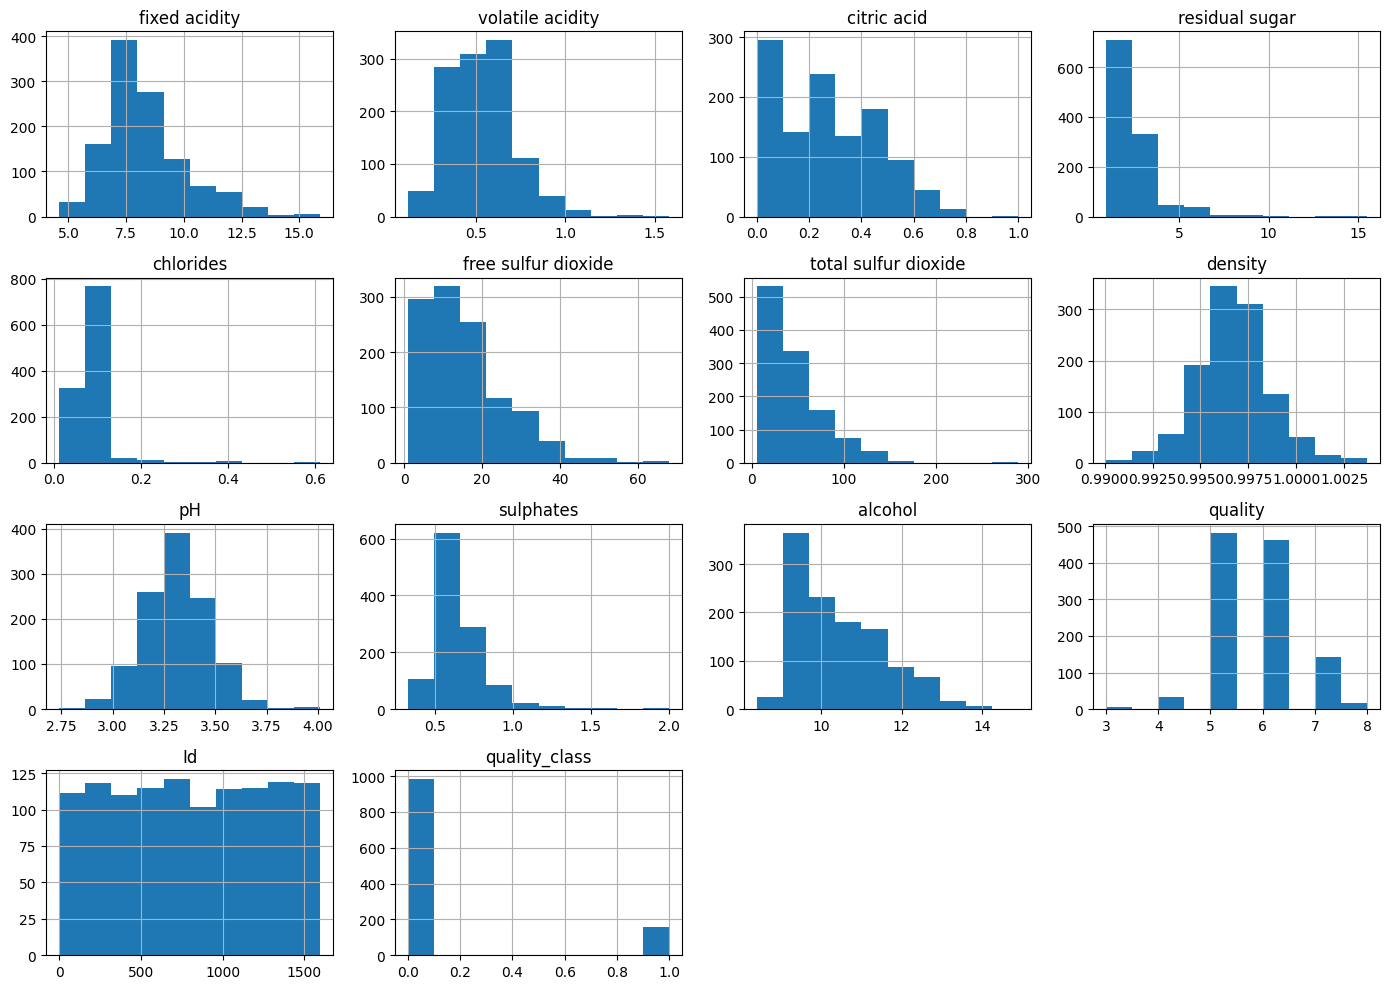

In [20]:
df.hist(figsize=(14,10))
plt.tight_layout()
plt.show()

Balanceamento das Classes

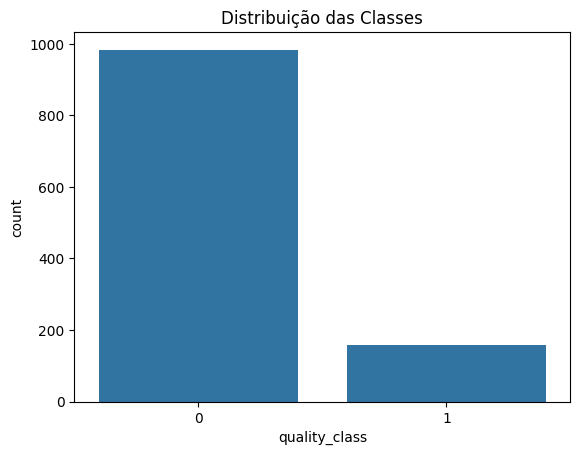

In [21]:
sns.countplot(x='quality_class', data=df)
plt.title('Distribuição das Classes')
plt.show()

Correlação

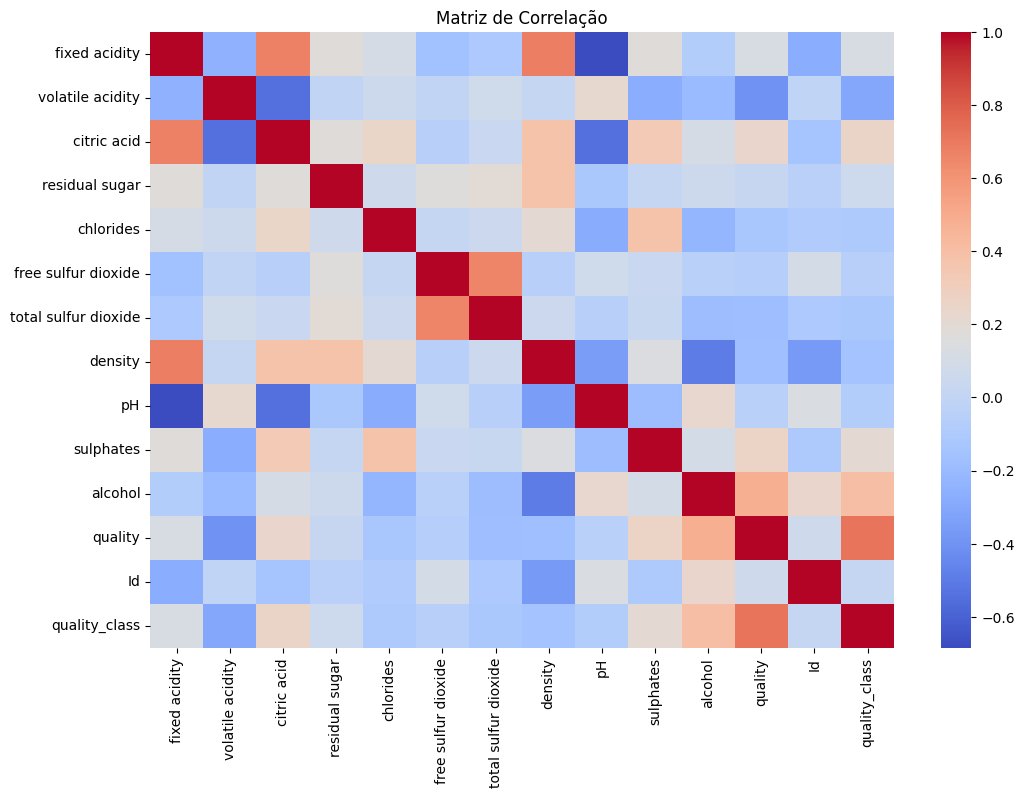

In [22]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True),
            cmap='coolwarm',
            annot=False)

plt.title('Matriz de Correlação')
plt.show()

In [24]:
corr = df.corr(numeric_only=True)['quality']

corr.sort_values(ascending=False)

,quality
quality,1.000000
quality_class,0.720433
alcohol,0.484866
sulphates,0.257710
citric acid,0.240821
fixed acidity,0.121970
Id,0.069708
residual sugar,0.022002
pH,-0.052453
free sulfur dioxide,-0.063260


Outliers

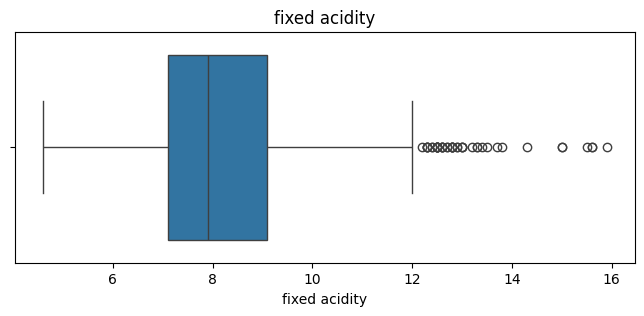

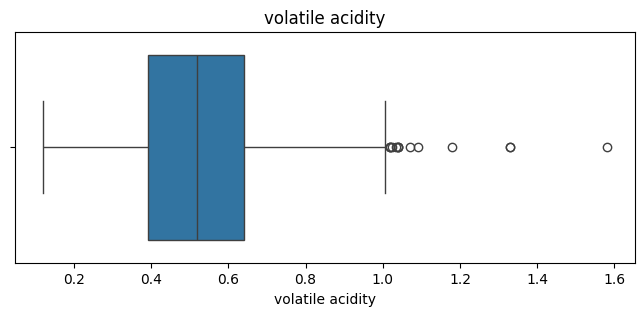

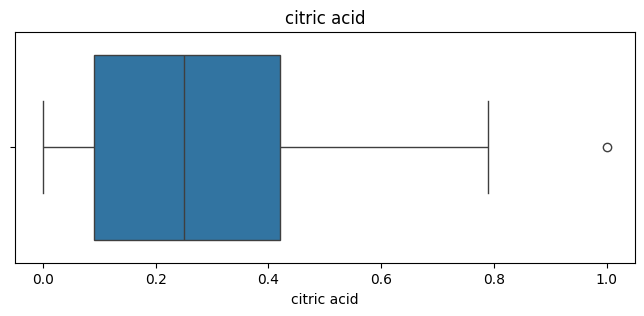

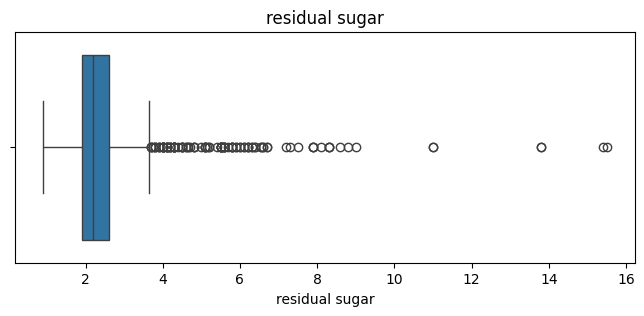

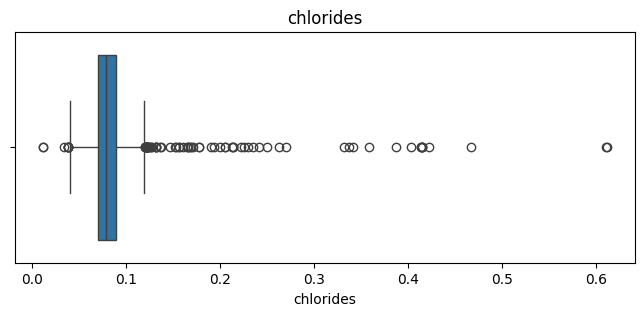

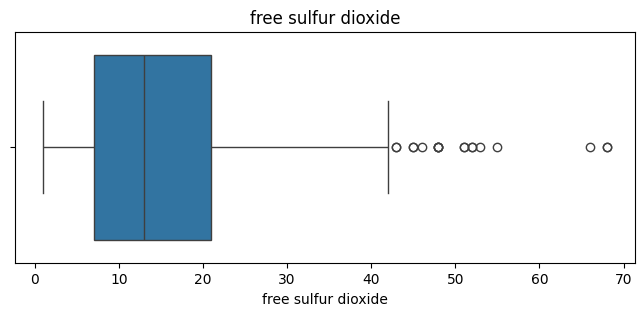

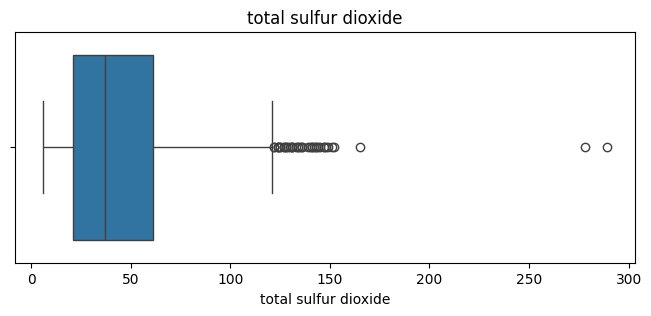

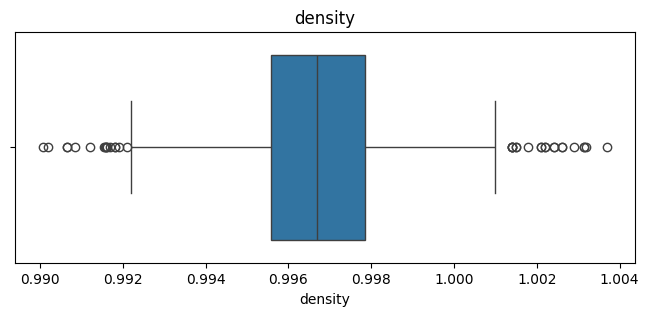

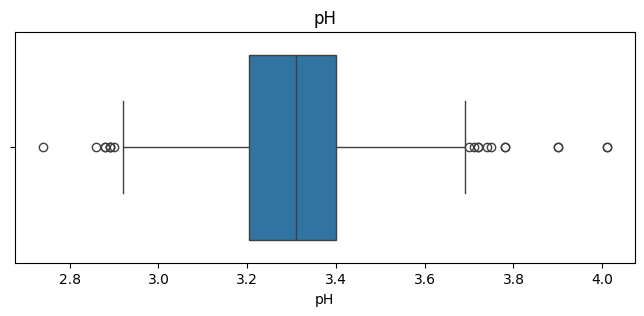

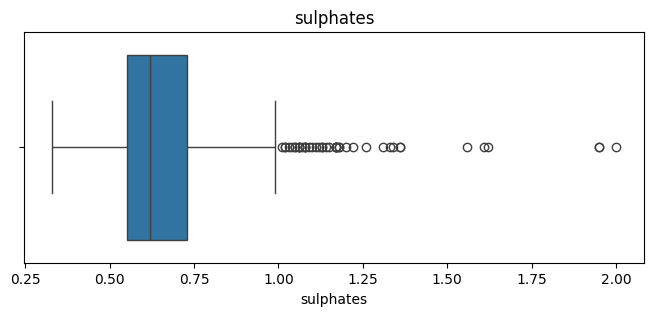

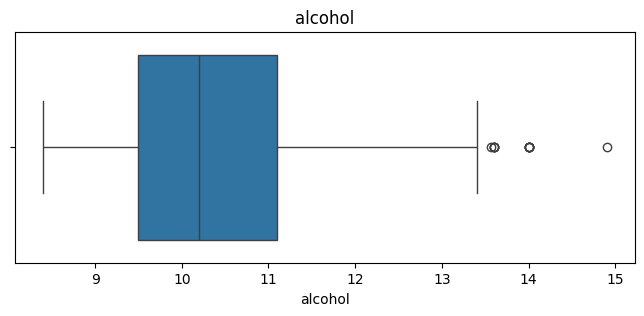

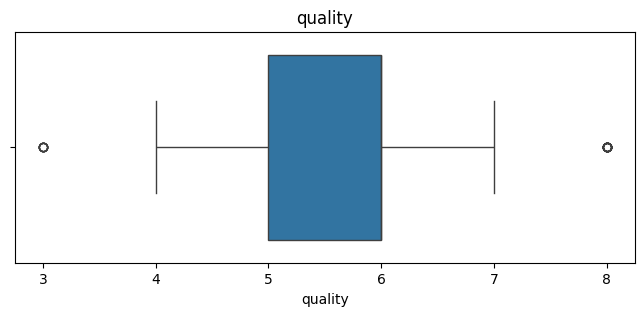

In [25]:
for col in df.columns[:-2]:
    plt.figure(figsize=(8,3))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

Seleção das Variáveis

In [34]:
X = df.drop(['quality', 'quality_class'], axis=1)

if 'Id' in X.columns:
    X = X.drop('Id', axis=1)

y = df['quality_class']

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

Modelo1- Regressão Logística

In [39]:
pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression())
])

pipeline_lr.fit(X_train, y_train)

pred_lr = pipeline_lr.predict(X_test)
prob_lr = pipeline_lr.predict_proba(X_test)[:,1]

Avaliação

In [41]:
print("Accuracy:", accuracy_score(y_test, pred_lr))
print("Precision:", precision_score(y_test, pred_lr))
print("Recall:", recall_score(y_test, pred_lr))
print("F1:", f1_score(y_test, pred_lr))
print("ROC AUC:", roc_auc_score(y_test, prob_lr))

Accuracy: 0.8646288209606987
Precision: 0.5238095238095238
Recall: 0.34375
F1: 0.41509433962264153
ROC AUC: 0.8418464467005077


In [42]:
print(classification_report(y_test, pred_lr))

              precision    recall  f1-score   support

           0       0.90      0.95      0.92       197
           1       0.52      0.34      0.42        32

    accuracy                           0.86       229
   macro avg       0.71      0.65      0.67       229
weighted avg       0.85      0.86      0.85       229



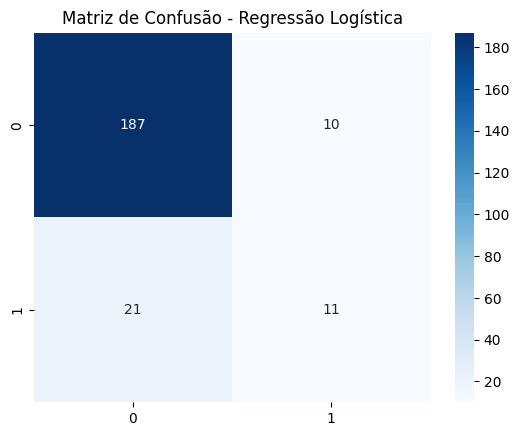

In [43]:
cm = confusion_matrix(y_test, pred_lr)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusão - Regressão Logística")
plt.show()

Modelo 2- Random Forest

In [45]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)
prob_rf = rf.predict_proba(X_test)[:,1]

Avaliação do modelo 2

In [46]:
print("Accuracy:", accuracy_score(y_test, pred_rf))
print("Precision:", precision_score(y_test, pred_rf))
print("Recall:", recall_score(y_test, pred_rf))
print("F1:", f1_score(y_test, pred_rf))
print("ROC AUC:", roc_auc_score(y_test, prob_rf))

Accuracy: 0.9126637554585153
Precision: 0.75
Recall: 0.5625
F1: 0.6428571428571429
ROC AUC: 0.911881345177665


Matriz de Confusão

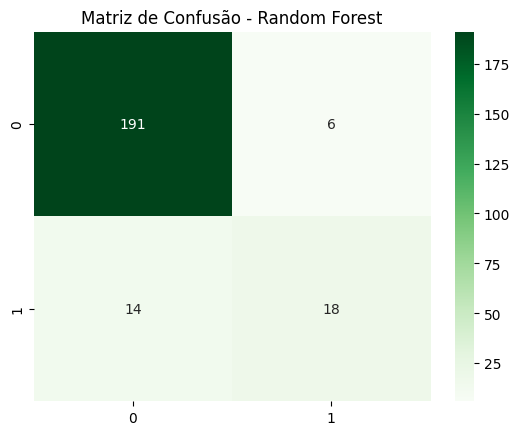

In [47]:
cm = confusion_matrix(y_test, pred_rf)

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Greens')

plt.title("Matriz de Confusão - Random Forest")
plt.show()

Comparação dos Modelos

In [48]:

resultados = pd.DataFrame({
    'Modelo':['Regressão Logística','Random Forest'],
    'Accuracy':[
        accuracy_score(y_test,pred_lr),
        accuracy_score(y_test,pred_rf)
    ],
    'Precision':[
        precision_score(y_test,pred_lr),
        precision_score(y_test,pred_rf)
    ],
    'Recall':[
        recall_score(y_test,pred_lr),
        recall_score(y_test,pred_rf)
    ],
    'F1':[
        f1_score(y_test,pred_lr),
        f1_score(y_test,pred_rf)
    ]
})

resultados


,Modelo,Accuracy,Precision,Recall,F1
0,Regressão Logística,0.864629,0.52381,0.34375,0.415094
1,Random Forest,0.912664,0.75000,0.56250,0.642857


Interpretação dos resultados- Importância das Variáveis

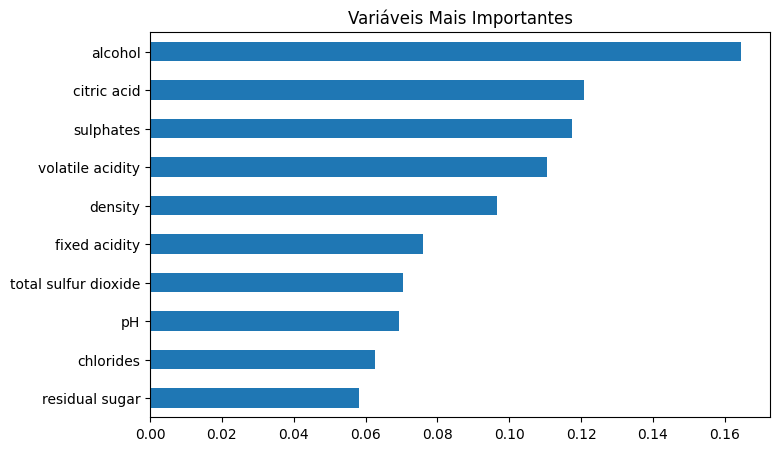

In [49]:
importancias = pd.Series(
    rf.feature_importances_,
    index=X.columns
)

importancias.sort_values().tail(10).plot(
    kind='barh',
    figsize=(8,5)
)

plt.title("Variáveis Mais Importantes")
plt.show()

Principais Conclusões
O modelo Random Forest apresentou melhor desempenho.
O teor alcoólico foi uma das variáveis mais relevantes.
A acidez volátil apresentou correlação negativa com a qualidade.
Sulfatos e ácido cítrico contribuíram positivamente para classificação dos vinhos.
O modelo pode auxiliar produtores na previsão da qualidade final do